In [10]:
from pathlib import Path
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

DATA_PATH = Path("data/processed/ChargingRecords_cleaned.csv")

if not DATA_PATH.exists():
    DATA_PATH = Path("data/processed/ChargingRecords_features.csv")

if not DATA_PATH.exists():
    DATA_PATH = Path("ChargingRecords_cleaned.csv")

if not DATA_PATH.exists():
    raise FileNotFoundError("Cleaned dataset not found.")

df = pd.read_csv(DATA_PATH)

df["Demand"] = pd.to_numeric(df["Demand"], errors="coerce")
df = df.dropna(subset=["Demand"]).copy()

print("Dataset loaded:", df.shape)
display(df.head())

Dataset loaded: (72799, 32)


,UserID,ChargerID,StartDay,StartTime,EndDay,EndTime,StartDatetime,EndDatetime,Duration,Demand,...,Location_golf,Location_hotel,Location_market,Location_public area,Location_public institution,Location_public parking lot,Location_resort,Location_restaurant,Location_sightseeing,ChargerType_1
0,0,1,15,20:54:02,2022-09-15,23:59:13,2022-09-15 20:54:02,2022-09-15 23:59:13,185,20.36,...,0,1,0,0,0,0,0,0,0,0
1,0,1,14,20:01:05,2022-09-14,21:31:04,2022-09-14 20:01:05,2022-09-14 21:31:04,90,10.19,...,0,1,0,0,0,0,0,0,0,0
2,0,1,14,18:54:30,2022-09-14,19:54:29,2022-09-14 18:54:30,2022-09-14 19:54:29,60,6.78,...,0,1,0,0,0,0,0,0,0,0
3,0,1,29,18:32:51,2022-09-30,0:16:42,2022-09-29 18:32:51,2022-09-30 00:16:42,344,37.65,...,0,1,0,0,0,0,0,0,0,0
4,0,1,25,19:30:15,2022-09-26,0:30:14,2022-09-25 19:30:15,2022-09-26 00:30:14,300,33.81,...,0,1,0,0,0,0,0,0,0,0


In [11]:
threshold = df["Demand"].median()

df["DemandCategory"] = np.where(
    df["Demand"] >= threshold,
    1,
    0
)

print("Demand threshold:", threshold)
print("0 = Normal Demand")
print("1 = High Demand")

display(df["DemandCategory"].value_counts())

Demand threshold: 14.1
0 = Normal Demand
1 = High Demand


DemandCategory
1    36434
0    36365
Name: count, dtype: int64

In [12]:
exclude_columns = [
    "Demand",
    "DemandCategory",
    "UserID",
    "ChargerID",
    "StartDatetime",
    "EndDatetime",
    "EndDay",
    "EndTime",
    "Duration",
    "DurationHours",
    "StartDayName"
]

X = df.drop(
    columns=[c for c in exclude_columns if c in df.columns]
)

y = df["DemandCategory"]

# Remove columns containing only missing values
X = X.dropna(axis=1, how="all")

print("Features:", X.shape)
print("Target:", y.shape)
print("Feature names:", X.columns.tolist())

Features: (72799, 21)
Target: (72799,)
Feature names: ['StartDay', 'StartTime', 'StartHour', 'StartDayOfWeek', 'StartMonth', 'IsWeekend', 'ChargerCompany_1', 'Location_apartment', 'Location_bus garage', 'Location_camping', 'Location_company', 'Location_golf', 'Location_hotel', 'Location_market', 'Location_public area', 'Location_public institution', 'Location_public parking lot', 'Location_resort', 'Location_restaurant', 'Location_sightseeing', 'ChargerType_1']


In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 58239
Testing records: 14560


In [14]:
numeric_features = X_train.select_dtypes(
    include=["number", "bool"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    exclude=["number", "bool"]
).columns.tolist()

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OrdinalEncoder(
        handle_unknown="use_encoded_value",
        unknown_value=-1
    ))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_transformer, numeric_features),
    ("categorical", categorical_transformer, categorical_features)
])

print("Preprocessing ready!")

Preprocessing ready!


In [15]:
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=30,
        max_depth=10,
        max_features=0.7,
        random_state=42,
        n_jobs=2,
        class_weight="balanced"
    ))
])

print("Training classification model...")

model.fit(X_train, y_train)

y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

print("Training completed!")

Training classification model...
Training completed!


In [16]:
results = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(
        y_test, y_pred, zero_division=0
    ),
    "Recall": recall_score(
        y_test, y_pred, zero_division=0
    ),
    "F1 Score": f1_score(
        y_test, y_pred, zero_division=0
    ),
    "ROC-AUC": roc_auc_score(y_test, y_prob)
}

results_df = pd.DataFrame(
    [results]
).round(4)

display(results_df)

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Normal Demand", "High Demand"],
    zero_division=0
))

,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,0.6445,0.6435,0.6497,0.6465,0.6945



Classification Report:
               precision    recall  f1-score   support

Normal Demand       0.65      0.64      0.64      7273
  High Demand       0.64      0.65      0.65      7287

     accuracy                           0.64     14560
    macro avg       0.64      0.64      0.64     14560
 weighted avg       0.64      0.64      0.64     14560



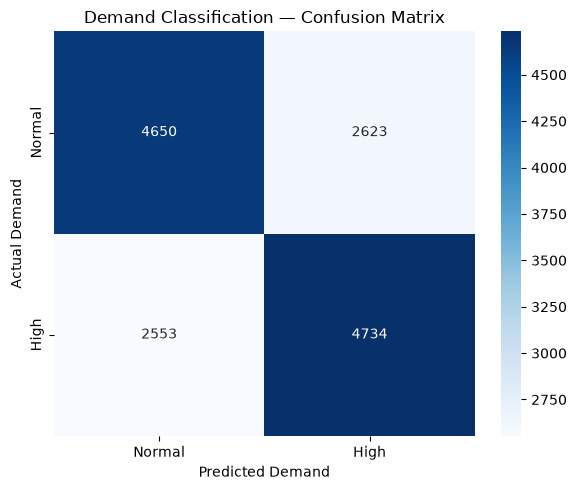

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normal", "High"],
    yticklabels=["Normal", "High"]
)

plt.title("Demand Classification — Confusion Matrix")
plt.xlabel("Predicted Demand")
plt.ylabel("Actual Demand")
plt.tight_layout()
plt.show()

In [18]:
import joblib

MODEL_DIR = Path("models")
REPORT_DIR = Path("reports")

MODEL_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

joblib.dump(
    model,
    MODEL_DIR / "demand_classification_model.joblib"
)

results_df.to_csv(
    REPORT_DIR / "classification_results.csv",
    index=False
)

predictions_df = pd.DataFrame({
    "Actual_Demand_Category": y_test.to_numpy(),
    "Predicted_Demand_Category": y_pred,
    "High_Demand_Probability": y_prob
})

predictions_df.to_csv(
    REPORT_DIR / "classification_predictions.csv",
    index=False
)

print("Classification completed successfully!")
print("Model saved:", MODEL_DIR / "demand_classification_model.joblib")
print("Results saved:", REPORT_DIR.resolve())

Classification completed successfully!
Model saved: models\demand_classification_model.joblib
Results saved: C:\Users\kavee\OneDrive\Desktop\EV Charging Demand Prediction and Usage Pattern Analysis\notebook\reports
